# SET on parallel MNIST

SET (sparse evolutionary training), written from scratch, on the non-stationary parallel MNIST problem of
`analysis/set_analysis_v2`, with the configuration that did best there. SET, a block sparse network and two static
sparse networks are the baselines for other structure search methods.

**Problem.** Each sample concatenates $T$ independently drawn MNIST training images (28×28, each pixel standardized
over the training set), and each task's target is its own image's label. Every $2000 / T$ steps, one task (chosen at
random) gets a new random mapping from digits to labels, so each task changes about every 2000 steps. The loss is the
sum of each task's softmax cross-entropy, one sample per step. $T$ is `N_TASKS`, 8 by default; the connection budget and
SET's hidden units scale with it, so each task's share stays the same.

**Network.** $784T$ inputs → $48T$ leaky-ReLU hidden units (LTUs for network Autostep) → $10T$ linear outputs ($T$ groups of 10 logits), no
biases; at 8 tasks, 6272 → 384 → 80. It is sparse, with block sparse's budget of $3176T$ connections on average (25,408
at 8 tasks): as in SET, each layer starts as a random graph in which each possible connection exists with probability
$\epsilon (n_\text{in} + n_\text{out}) / (n_\text{in} n_\text{out})$, with $\epsilon \approx 3.57$ setting the
total. Weights start LeCun uniform over each unit's fan-in.

**SET.** Plain SGD with step size $2^{-6}$ (chosen at 8 tasks). Every 500 steps, in each layer separately, the 1% of connections with the
lowest utility are removed, and each unit gets back as many connections as it lost, from sources chosen uniformly at
random among those it isn't connected to. So every unit keeps its starting fan-in. A connection's utility is a running
mean (rate 0.002) of $|\text{source value}| \cdot |w|$, bias-corrected for the connection's age. New connections get
LeCun uniform weights and start with zero utility.

**Metrics.** Online loss per task and online accuracy (over every task), on each sample before learning from it.
*Path purity* is the share of all input → hidden → output path weight (the product of $|w|$ along the path) that starts
and ends in the same task: 1 when no path crosses tasks, about $1/T$ when the tasks are mixed evenly. *Allocation* is
$(1 - \text{largest task's share of units}) / (1 - 1/T)$, counting each hidden unit for the task whose outputs it feeds
most and leaving out units that feed no output: 1 when every task has the same number of units, 0 when all feed one task.

Everything is recorded at step 1, then averaged over each window of 2000 steps (purity and allocation are computed from
the weights after every step), and plotted as the mean ± 2 standard errors over 30 seeds. Seed $s$ gives every method
the same images and label changes.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [ ]:
# --- Problem ---
N_TASKS = 4                          # the label-change rate, connection budget and hidden units scale with it
N_PIXELS = 28 * 28
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_INPUTS = N_TASKS * N_PIXELS
N_OUTPUTS = N_TASKS * N_CLASSES
BLOCK_UNITS_PER_TASK = 4             # block sparse's hidden units per task, which set the connection budget:
N_CONNECTIONS = N_TASKS * BLOCK_UNITS_PER_TASK * (N_PIXELS + N_CLASSES)        # 25,408 at 8 tasks
N_HIDDEN = 48 * N_TASKS              # SET's hidden units, 384 at 8 tasks

# --- SET ---
STEP_SIZE = 2 ** -6
EVOLVE_PERIOD = 500                  # steps between prune-and-regrow events
ZETA = 0.01                          # fraction of each layer's connections replaced at each event
UTILITY_DECAY = 0.998                # decay of each connection's running utility

# --- Training ---
NUM_STEPS = 200_000
N_SEEDS = 5
WINDOW = 2000                        # each window records its mean loss, accuracy, path purity and allocation

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, N_PIXELS) / 255.0
std = images.std(0)
IMAGES = jnp.asarray((images - images.mean(0)) / np.where(std < 1e-6, 1.0, std))     # each pixel standardized
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
INPUT_TASK = jnp.repeat(jnp.arange(N_TASKS), N_PIXELS)
OUTPUT_TASK = jnp.repeat(jnp.arange(N_TASKS), N_CLASSES)
METRICS = ('loss', 'accuracy', 'purity', 'allocation')


# Both metrics take each hidden unit's total |weight| from every task's inputs (`reads`) and to every task's outputs
# (`feeds`), each shaped (hidden unit, task).
def path_purity(reads, feeds):
    # The share of all input -> hidden -> output path weight (the product of |w| along the path) that starts and ends
    # in the same task.
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(1) * feeds.sum(1)), 1e-30)


def allocation(feeds):
    # How evenly the hidden units are split between the tasks, counting each unit for the task whose outputs it feeds
    # most and leaving out units that feed no output: 1 when every task has the same number, 0 when all feed one task.
    feeding = feeds.sum(1) > 0
    largest = jnp.zeros(N_TASKS).at[feeds.argmax(1)].add(feeding).max() / jnp.maximum(feeding.sum(), 1)
    return (1 - largest) / (1 - 1 / N_TASKS)

## SET

In [5]:
EPSILON = N_CONNECTIONS / (N_INPUTS + N_OUTPUTS + 2 * N_HIDDEN)     # SET's density parameter


class Layer(NamedTuple):
    # A sparse layer stored by unit: each unit's connections fill its first slots, and the other slots stay unused.
    w: jax.Array              # (unit, slot) weights, 0 in unused slots
    src: jax.Array            # (unit, slot) the source each slot reads
    used: jax.Array           # (unit, slot) whether the slot holds a connection; fixed, so every unit keeps its fan-in
    utility: jax.Array        # (unit, slot) running mean of |source value| |w|
    age: jax.Array            # (unit, slot) steps since the connection was made


class Net(NamedTuple):
    hidden: Layer             # input -> hidden
    output: Layer             # hidden -> output
    key: jax.Array            # for regrowth


def new_weights(key, used):
    # LeCun uniform over each unit's fan-in, in the used slots.
    bound = jnp.sqrt(3.0 / jnp.maximum(used.sum(1, keepdims=True), 1))
    return jax.random.uniform(key, used.shape, minval=-1.0, maxval=1.0) * bound * used


def init_layer(key, n_units, n_sources):
    # SET's random start: each possible connection exists with probability EPSILON (n_units + n_sources) /
    # (n_units n_sources). Each unit gets twice its expected fan-in in slots.
    p = EPSILON * (n_units + n_sources) / (n_units * n_sources)
    connect_key, weight_key = jax.random.split(key)
    connected = jax.random.bernoulli(connect_key, p, (n_units, n_sources))
    src = jnp.argsort(~connected, axis=1, stable=True)[:, :int(np.ceil(2 * p * n_sources))]    # connected ones first
    used = jnp.take_along_axis(connected, src, axis=1)
    return Layer(new_weights(weight_key, used), src, used, jnp.zeros(used.shape), jnp.zeros(used.shape, jnp.int32))


def init_net(key):
    hidden_key, output_key, key = jax.random.split(key, 3)
    return Net(init_layer(hidden_key, N_HIDDEN, N_INPUTS), init_layer(output_key, N_OUTPUTS, N_HIDDEN), key)


def forward(w, net, x):
    # Returns the logits, (task, class), and each layer's source values.
    h = jax.nn.leaky_relu(jnp.sum(w[0] * x[net.hidden.src], axis=1))
    return jnp.sum(w[1] * h[net.output.src], axis=1).reshape(N_TASKS, N_CLASSES), (x, h)


def set_step(net, x, labels):
    # One SGD step on the summed softmax cross-entropy of every task. Each connection's utility is updated with this
    # sample and the weights that produced it. Returns the new net, the loss and the fraction of tasks classified
    # correctly.
    def loss_fn(w):
        logits, sources = forward(w, net, x)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (logits, sources)

    (loss, (logits, sources)), grads = jax.value_and_grad(loss_fn, has_aux=True)((net.hidden.w, net.output.w))

    def update(layer, grad, source):
        utility = UTILITY_DECAY * layer.utility + (1 - UTILITY_DECAY) * jnp.abs(source[layer.src] * layer.w)
        return layer._replace(w=layer.w - STEP_SIZE * grad * layer.used, utility=utility, age=layer.age + 1)

    hidden, output = map(update, (net.hidden, net.output), grads, sources)
    return net._replace(hidden=hidden, output=output), loss, jnp.mean(logits.argmax(1) == labels)


def evolve_layer(layer, key, n_sources):
    # Removes the ZETA fraction of the layer's connections with the lowest utility (bias-corrected for the connection's
    # age), then gives each unit back the connections it lost, from sources chosen at random among those it isn't
    # connected to. New connections get new weights and start with zero utility.
    score = jnp.where(layer.used, layer.utility / (1 - UTILITY_DECAY ** jnp.maximum(layer.age, 1)), jnp.inf)
    n_pruned = jnp.floor(ZETA * layer.used.sum()).astype(jnp.int32)
    pruned = layer.used & (score <= jnp.sort(score.ravel())[jnp.maximum(n_pruned - 1, 0)]) & (n_pruned > 0)

    src_key, weight_key = jax.random.split(key)
    n_units = layer.src.shape[0]
    taken = jnp.zeros((n_units, n_sources), bool).at[jnp.arange(n_units)[:, None], layer.src].max(layer.used & ~pruned)
    free = jnp.argsort(jnp.where(taken, 2.0, jax.random.uniform(src_key, taken.shape)), axis=1)  # untaken, shuffled
    new_src = jnp.take_along_axis(free, jnp.cumsum(pruned, axis=1) - 1, axis=1)     # a unit's k-th pruned slot takes
    return layer._replace(w=jnp.where(pruned, new_weights(weight_key, layer.used), layer.w),       # the k-th of them
                          src=jnp.where(pruned, new_src, layer.src),
                          utility=jnp.where(pruned, 0.0, layer.utility), age=jnp.where(pruned, 0, layer.age))


def evolve(net):
    key, hidden_key, output_key = jax.random.split(net.key, 3)
    return Net(evolve_layer(net.hidden, hidden_key, N_INPUTS), evolve_layer(net.output, output_key, N_HIDDEN), key)


def task_weights(net):
    # Each hidden unit's total |weight| from every task's inputs and to every task's outputs, (hidden unit, task).
    reads = jnp.zeros((N_HIDDEN, N_TASKS)).at[jnp.arange(N_HIDDEN)[:, None], INPUT_TASK[net.hidden.src]].add(
        jnp.abs(net.hidden.w))
    feeds = jnp.zeros((N_HIDDEN, N_TASKS)).at[net.output.src, OUTPUT_TASK[:, None]].add(jnp.abs(net.output.w))
    return reads, feeds

## Block sparse

The ideal connectivity at SET's budget: 4 hidden units per task, each reading only its own task's 784 inputs and
feeding only its own task's 10 logits (3176 connections per task, 25,408 at 8 tasks). Weights start LeCun uniform over
each unit's fan-in and are trained with plain SGD, with no structure changes, at step size $2^{-8}$, the best in the
earlier block sparse sweep of this problem at 4 units per task, for every task count from 4 to 32
(`analysis/weight_pruning`). Its path purity and allocation are 1 by construction.

In [6]:
BLOCK_STEP_SIZE = 2 ** -8


class Block(NamedTuple):
    w1: jax.Array             # (task, unit, pixel): each task's hidden units' weights from that task's image
    w2: jax.Array             # (task, class, unit): each task's logits' weights from that task's hidden units


def init_block(key):
    # LeCun uniform over each unit's fan-in.
    draw = lambda key, shape: jax.random.uniform(key, shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / shape[-1])
    w1_key, w2_key = jax.random.split(key)
    return Block(draw(w1_key, (N_TASKS, BLOCK_UNITS_PER_TASK, N_PIXELS)),
                 draw(w2_key, (N_TASKS, N_CLASSES, BLOCK_UNITS_PER_TASK)))


def block_step(net, x, labels):
    # One SGD step on the summed softmax cross-entropy of every task. Returns the new net, the loss and the fraction of
    # tasks classified correctly.
    def loss_fn(net):
        h = jax.nn.leaky_relu(jnp.einsum('tup,tp->tu', net.w1, x.reshape(N_TASKS, N_PIXELS)))
        logits = jnp.einsum('tcu,tu->tc', net.w2, h)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), logits

    (loss, logits), grads = jax.value_and_grad(loss_fn, has_aux=True)(net)
    return jax.tree.map(lambda w, g: w - BLOCK_STEP_SIZE * g, net, grads), loss, jnp.mean(logits.argmax(1) == labels)


def block_task_weights(net):
    # Each hidden unit reads from and feeds only its own task, (hidden unit, task).
    own = jnp.repeat(jnp.eye(N_TASKS), BLOCK_UNITS_PER_TASK, axis=0)
    return own * jnp.abs(net.w1).sum(2).reshape(-1, 1), own * jnp.abs(net.w2).sum(1).reshape(-1, 1)

## Static sparse baselines

SET's random start (the same connections for the same seed), with no structure changes, trained with either:
- **SGD**, as in SET: step size $2^{-6}$, weights LeCun uniform.
- **Network Autostep**, from `sandbox/network_autostep/01_distractors.ipynb`:
  - LTU hidden units (0/1 step forward, sigmoid derivative backward) instead of leaky ReLU.
  - Autostep ($\tau = 10^4$) treating each layer as its own linear problem, so each weight is normalized by the squared
    value of its source unit. Every step-size starts at $\alpha_0 = 10^{-5}$, and the meta step-size is 0.01.
  - Centering: each hidden unit sends $h - m$, where $m$ is its running mean (rate $10^{-3}$, starting at 0.5), and the
    backward pass takes the gradient of $h - \mathbb{E}[h]$: the derivative with respect to input weight $k$ is
    $\sigma'(z)\,x_k - s_k$, where $s_k$ is a running mean of $\sigma'(z)\,x_k$ at the same rate, starting at 0.
  - Input centering: it reads each pixel's value / 255, not the problem's per-pixel standardized value (whose rarely
    lit pixels reach $|x| \approx 245$), minus the pixel's running mean (rate $10^{-3}$, bias-corrected so that early
    on it is the average of the images seen so far). Inputs don't depend on any weights, so there is no backward
    correction.
  - Small input weights: they start at $U(-\alpha_0, \alpha_0)$ instead of LeCun uniform. Output weights start at 0.

In [7]:
AUTOSTEP_INIT_STEP_SIZE = 1e-5       # alpha_0: every step-size starts here, and input weights start U(-alpha_0, alpha_0)
AUTOSTEP_META_STEP_SIZE = 0.02
AUTOSTEP_TAU = 1e4
CENTERING_RATE = 1e-3                # rate of the inputs' and hidden units' running means
AUTOSTEP = optax_idbd(meta_lr=AUTOSTEP_META_STEP_SIZE, init_lr=AUTOSTEP_INIT_STEP_SIZE, autostep=True,
                      tau=AUTOSTEP_TAU, version='squared_inputs')

# The problem standardizes each pixel; network Autostep undoes that (x * std + mean) to read each pixel's value / 255.
PIXEL_MEAN = jnp.tile(images.mean(0), N_TASKS)
PIXEL_STD = jnp.tile(np.where(std < 1e-6, 1.0, std), N_TASKS)


class AutostepNet(NamedTuple):
    hidden: Layer             # input -> hidden, SET's sparse layer (its utility and age go unused)
    output: Layer             # hidden -> output
    opt: IDBDState            # Autostep's step-sizes and traces, for (hidden.w, output.w)
    input_trace: jax.Array    # (input,) running mean of each pixel / 255, before its bias correction
    n_samples: jax.Array      # samples seen, for that bias correction
    hidden_mean: jax.Array    # (hidden unit,) each hidden unit's running mean
    hidden_slope: jax.Array   # (hidden unit, slot) running mean of sigma'(z) x, each input weight's raw derivative


def init_autostep_net(key):
    # SET's start for the same key, with the input weights drawn from U(-alpha_0, alpha_0) instead and the output
    # weights at 0.
    net = init_net(key)
    w1 = jax.random.uniform(jax.random.fold_in(key, 1), net.hidden.w.shape, minval=-1.0, maxval=1.0)
    hidden = net.hidden._replace(w=w1 * AUTOSTEP_INIT_STEP_SIZE * net.hidden.used)
    output = net.output._replace(w=jnp.zeros(net.output.w.shape))
    opt = AUTOSTEP.init((hidden.w, output.w))
    return AutostepNet(hidden, output, opt, jnp.zeros(N_INPUTS), jnp.array(0), jnp.full(N_HIDDEN, 0.5),
                       jnp.zeros(hidden.w.shape))


def autostep_forward(w, net, x):
    # Returns the logits, (task, class), each layer's source value per slot (0 in unused slots), and the net's new running
    # statistics.
    # Inputs: each pixel / 255 minus its running mean, bias-corrected so that early on it is the average of the samples
    # seen so far. Like the hidden units' below, it is updated with this sample before it is used.
    pixels = x * PIXEL_STD + PIXEL_MEAN
    input_trace = net.input_trace + CENTERING_RATE * (pixels - net.input_trace)
    n_samples = net.n_samples + 1
    x = pixels - input_trace / (1 - (1 - CENTERING_RATE) ** n_samples)

    x_in = x[net.hidden.src] * net.hidden.used
    z = jnp.sum(w[0] * x_in, axis=1)
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = net.hidden_mean + CENTERING_RATE * (jax.lax.stop_gradient(h) - net.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))      # the LTU's surrogate slope
    slope = net.hidden_slope + CENTERING_RATE * (sigma_prime[:, None] * x_in - net.hidden_slope)
    # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
    # correction leaves the value unchanged.
    correction = jnp.sum(slope * w[0], axis=1)
    h = h - mean - correction + jax.lax.stop_gradient(correction)

    h_in = h[net.output.src] * net.output.used
    logits = jnp.sum(w[1] * h_in, axis=1).reshape(N_TASKS, N_CLASSES)
    state = {'input_trace': input_trace, 'n_samples': n_samples, 'hidden_mean': mean, 'hidden_slope': slope}
    return logits, (jax.lax.stop_gradient((x_in, h_in)), state)


def autostep_step(net, x, labels):
    # One network Autostep step on the summed softmax cross-entropy of every task. Returns the new net, the loss and the
    # fraction of tasks classified correctly.
    def loss_fn(w):
        logits, aux = autostep_forward(w, net, x)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (logits, aux)

    w = (net.hidden.w, net.output.w)
    (loss, (logits, (sources, state))), grads = jax.value_and_grad(loss_fn, has_aux=True)(w)
    updates, opt = AUTOSTEP.update((grads, None, sources), net.opt, w)
    hidden = net.hidden._replace(w=w[0] + updates[0])
    output = net.output._replace(w=w[1] + updates[1])
    return net._replace(hidden=hidden, output=output, opt=opt, **state), loss, jnp.mean(logits.argmax(1) == labels)

## Network Autostep with connectivity learning

The static network Autostep baseline, with every unit, in both layers, running a CI test on its own input slots,
treating them as a linear problem: its error $\delta$ is the loss's gradient with respect to its pre-activation (through
the LTU's surrogate slope), and its inputs are its sources' values, as Autostep sees them. A slot's utility is
$|w| + |h|$, $h$ being Autostep's trace, so a useful weight crossing zero after a label change keeps a large $|h|$. The
slot is cut once its utility is below the bound a dead weight's $|w| + |h|$ stays under 68% of the time at the same age,
$s(t)\,(1.61 + 0.39\, e^{-1.5 \tau})$, where $s(t) = \sqrt{\alpha\, \mathbb{E}[\delta^2] / 2 \cdot m_t}$ is a dead
weight's standard deviation, $m_t = 1 - \prod_k (1 - \alpha_k x_k^2)^2$ its maturity, $\tau = -\log(1 - m_t) / 2$ its
age, and $\mathbb{E}[\delta^2]$ the unit's running mean of $\delta^2$ (horizon 1000 steps, bias-corrected). A cut slot
reads a new source for the same unit, drawn uniformly from those the unit isn't connected to, and restarts: weight 0,
step-size $\alpha_0$, no traces, maturity 0. So every unit keeps its fan-in. No slot is cut before step 100,000.

In [ ]:
BAND_TRACE_HORIZON = 1_000           # horizon of each unit's running mean of delta^2
PRUNE_START = 100_000                # no slot is cut before this step


class CINet(NamedTuple):
    # AutostepNet's fields, then each layer's (hidden, output) connectivity-learning state.
    hidden: Layer
    output: Layer
    opt: IDBDState
    input_trace: jax.Array
    n_samples: jax.Array
    hidden_mean: jax.Array
    hidden_slope: jax.Array
    delta_sq: tuple           # (unit,) running mean of each unit's delta^2, before its bias correction
    log_imm: tuple            # (unit, slot) log(1 - maturity): 0 at birth, -inf once mature
    key: jax.Array            # for regrowth


def init_ci_net(key):
    # The static baseline's start for the same key. Every slot starts newborn.
    net = init_autostep_net(key)
    return CINet(*net, delta_sq=(jnp.zeros(N_HIDDEN), jnp.zeros(N_OUTPUTS)),
                 log_imm=(jnp.zeros(net.hidden.w.shape), jnp.zeros(net.output.w.shape)), key=jax.random.fold_in(key, 2))


def ci_test(w, h, alpha, x_sq, used, delta_sq, log_imm, pruning):
    # One layer's CI test on |w| + |h|, each unit (row) on its own slots. Returns the slots to cut (none unless
    # `pruning`) and the new log(1 - maturity).
    band = jnp.sqrt(alpha * delta_sq[:, None] / 2.0 * -jnp.expm1(log_imm))     # a dead weight's sd at the pre-update age
    bound = band * (1.61 + 0.39 * jnp.exp(0.75 * log_imm))                    # 68% of its |w| + |h|; exp(-1.5 tau)
    cut = pruning & used & (jnp.abs(w) + jnp.abs(h) < bound)
    new_log_imm = log_imm + 2.0 * jnp.log1p(-jnp.minimum(alpha * x_sq, 1.0))
    return cut, jnp.where(cut, 0.0, new_log_imm)


def regrow(layer, cut, key, n_sources):
    # Each cut slot reads a new source for the same unit, drawn uniformly from those the unit isn't connected to, with
    # weight 0.
    n_units = layer.src.shape[0]
    taken = jnp.zeros((n_units, n_sources), bool).at[jnp.arange(n_units)[:, None], layer.src].max(layer.used)
    free = jnp.argsort(jnp.where(taken, 2.0, jax.random.uniform(key, taken.shape)), axis=1)    # untaken, shuffled
    new_src = jnp.take_along_axis(free, jnp.cumsum(cut, axis=1) - 1, axis=1)   # a unit's k-th cut slot takes the k-th
    return layer._replace(w=jnp.where(cut, 0.0, layer.w), src=jnp.where(cut, new_src, layer.src))


def ci_step(net, x, labels):
    # One network Autostep step, then every unit's CI test on its slots, cutting and regrowing. Returns the new net, the
    # loss and the fraction of tasks classified correctly.
    logits, ((x_in, h_in), _) = autostep_forward((net.hidden.w, net.output.w), net, x)
    new, loss, accuracy = autostep_step(net, x, labels)

    # delta: the loss's gradient with respect to each unit's pre-activation, through the LTU's surrogate slope.
    delta_out = (jax.nn.softmax(logits) - jax.nn.one_hot(labels, N_CLASSES)).ravel()
    s = jax.nn.sigmoid(jnp.sum(net.hidden.w * x_in, axis=1))
    delta_hidden = jnp.zeros(N_HIDDEN).at[net.output.src].add(net.output.w * delta_out[:, None]) * s * (1 - s)
    gain = 1.0 / BAND_TRACE_HORIZON
    delta_sq = tuple(v + gain * (d ** 2 - v) for v, d in zip(net.delta_sq, (delta_hidden, delta_out)))
    unbias = -jnp.expm1(new.n_samples * jnp.log1p(-gain))      # so delta_sq reads unbiased from step 1

    pruning = new.n_samples > PRUNE_START
    cuts, log_imm = zip(*[
        ci_test(layer.w, h, jnp.exp(beta), source ** 2, layer.used, v / unbias, log_imm, pruning)
        for layer, h, beta, source, v, log_imm in zip((new.hidden, new.output), new.opt.h, new.opt.beta, (x_in, h_in),
                                                      delta_sq, net.log_imm)])

    # Cut slots restart: weight 0, step-size alpha_0, no traces, maturity 0.
    restart = lambda tree, value: tuple(jnp.where(cut, value, t) for cut, t in zip(cuts, tree))
    opt = new.opt._replace(beta=restart(new.opt.beta, new.opt.init_beta), h=restart(new.opt.h, 0.0),
                           v=restart(new.opt.v, 0.0))
    hidden_key, output_key = jax.random.split(jax.random.fold_in(net.key, net.n_samples))
    return new._replace(hidden=regrow(new.hidden, cuts[0], hidden_key, N_INPUTS),
                        output=regrow(new.output, cuts[1], output_key, N_HIDDEN), opt=opt,
                        hidden_slope=jnp.where(cuts[0], 0.0, new.hidden_slope), delta_sq=delta_sq,
                        log_imm=log_imm), loss, accuracy

## Training

In [8]:
N_WINDOWS = NUM_STEPS // WINDOW


def train(key, stream, init, learn, task_weights, evolve):
    # One method on one seed: `init(key)` makes its network, `learn(net, x, labels)` takes one online step and returns
    # (net, loss, accuracy), `task_weights(net)` gives the metrics' (reads, feeds), and `evolve(net)` runs after every
    # EVOLVE_PERIOD steps. Step 1 on its own, then NUM_STEPS online steps in windows. Returns the loss per task,
    # accuracy, path purity and allocation: at step 1, then averaged over every window. Loss and accuracy are on each
    # sample before learning from it; purity and allocation are of the weights after each step's update.
    def step(net, stream):
        stream, (x, labels) = next_sample(stream)
        net, loss, accuracy = learn(net, x, labels)
        reads, feeds = task_weights(net)
        return net, stream, {'loss': loss / N_TASKS, 'accuracy': accuracy, 'purity': path_purity(reads, feeds),
                             'allocation': allocation(feeds)}

    def one_step(carry, _):
        net, stream, total = carry
        net, stream, values = step(net, stream)
        return (net, stream, jax.tree.map(jnp.add, total, values)), None

    def evolve_period(carry, _):
        net, stream, total = jax.lax.scan(one_step, carry, length=EVOLVE_PERIOD)[0]
        return (evolve(net), stream, total), None

    def window(carry, _):
        zeros = dict.fromkeys(METRICS, 0.0)
        net, stream, total = jax.lax.scan(evolve_period, (*carry, zeros), length=WINDOW // EVOLVE_PERIOD)[0]
        return (net, stream), jax.tree.map(lambda t: t / WINDOW, total)

    net, stream, first = step(init(key), stream)
    values = jax.lax.scan(window, (net, stream), length=N_WINDOWS)[1]
    return jax.tree.map(lambda f, v: jnp.concatenate([f[None], v]), first, values)


def seeds():
    # Every seed's init key and stream. Seed s uses init key s and stream s in every run, so runs are paired.
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS)
    return keys, jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), N_SEEDS))


def run(init, learn, task_weights, evolve=lambda net: net):
    # A method (as in train()) on every seed at once. Returns per-seed records of every metric, (seed, step 1 + window).
    return jax.tree.map(np.asarray, jax.jit(jax.vmap(
        lambda key, stream: train(key, stream, init, learn, task_weights, evolve)))(*seeds()))

## Results

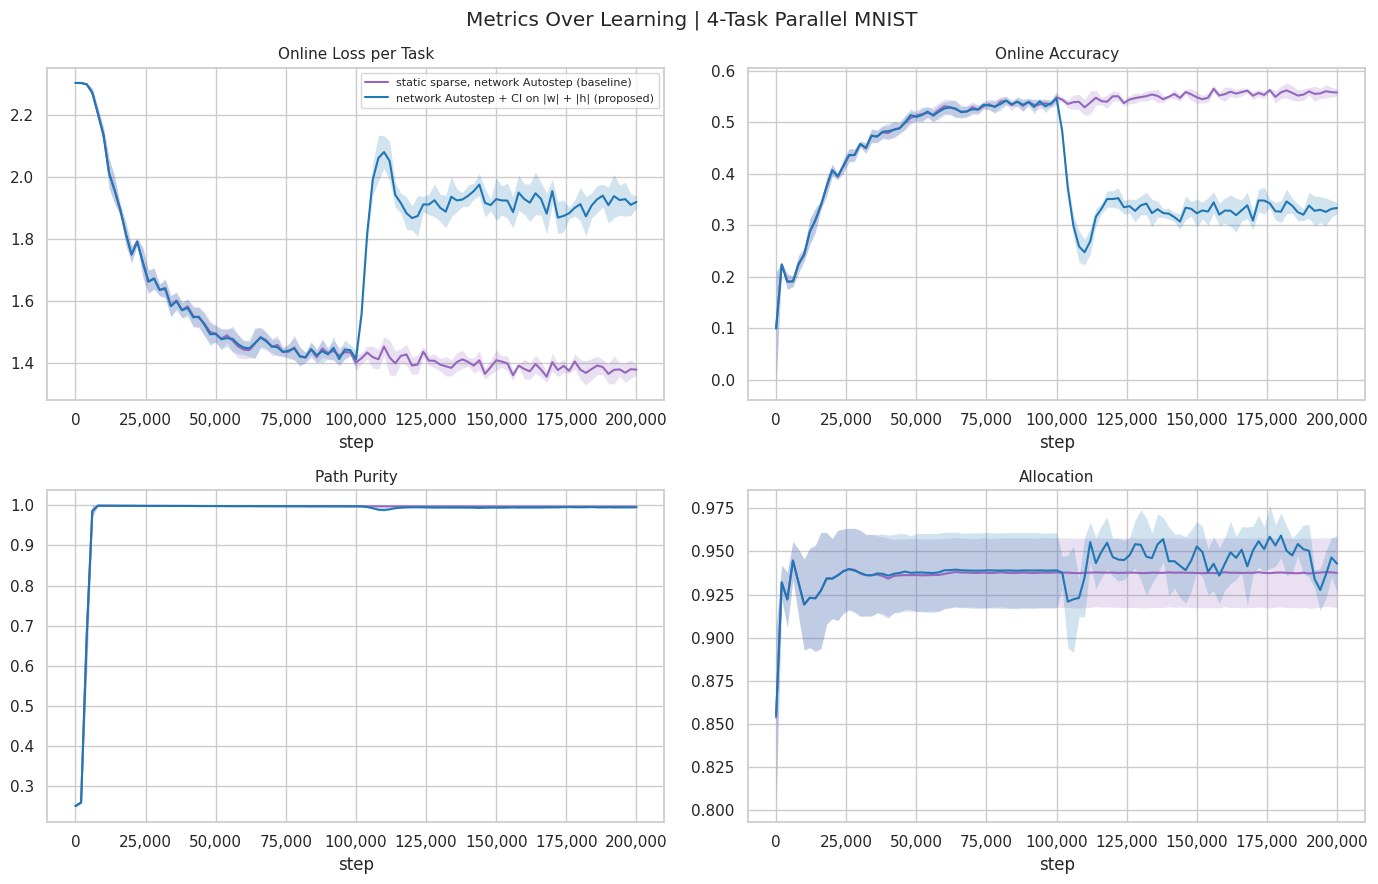

In [ ]:
STEPS = 1 + np.arange(N_WINDOWS + 1) * WINDOW     # step 1, then the end of every window


def plot_runs(runs, colors):
    # Every metric over training for each run in `runs` (mean +- 2 SE over seeds), drawn in `colors[label]`.
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, (key, title) in zip(axes.flat, [('loss', 'Online Loss per Task'), ('accuracy', 'Online Accuracy'),
                                       ('purity', 'Path Purity'), ('allocation', 'Allocation')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(STEPS, mean, color=colors[label], lw=1.5, label=label)
            ax.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.set_xlabel('step')
        ax.xaxis.set_major_formatter('{x:,.0f}')
        ax.set_title(title, fontsize=11)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'Metrics Over Learning | {N_TASKS}-Task Parallel MNIST')
    fig.tight_layout()
    plt.show()


runs = {# 'SET (baseline)': run(init_net, set_step, task_weights, evolve),
        # 'block sparse (baseline)': run(init_block, block_step, block_task_weights),
        # 'static sparse, SGD (baseline)': run(init_net, set_step, task_weights),
        'static sparse, network Autostep (baseline)': run(init_autostep_net, autostep_step, task_weights),
        'network Autostep + CI on |w| + |h| (proposed)': run(init_ci_net, ci_step, task_weights)}
plot_runs(runs, {'SET (baseline)': 'tab:red', 'block sparse (baseline)': '#67000d',
                 'static sparse, SGD (baseline)': 'tab:orange', 'static sparse, network Autostep (baseline)': 'tab:purple',
                 'network Autostep + CI on |w| + |h| (proposed)': 'tab:blue'})

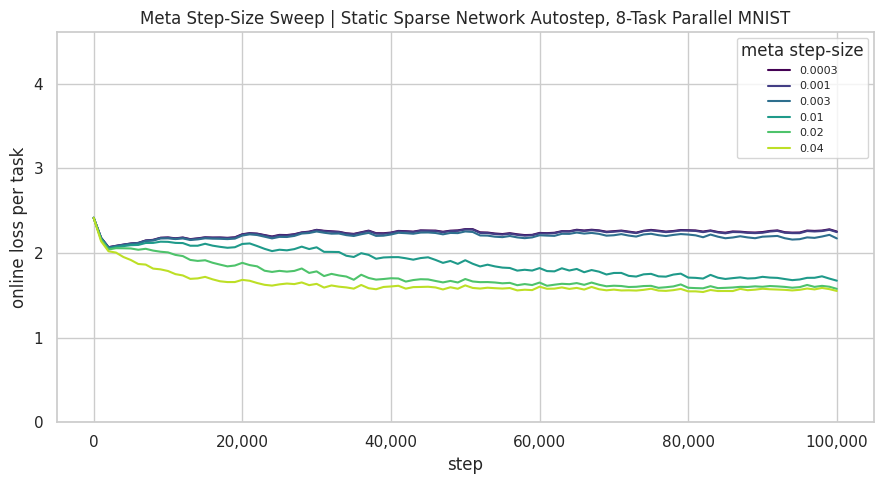

In [10]:
# Meta step-size sweep for static sparse network Autostep: every value trained at once, on the same N_SEEDS seeds.
SWEEP_META_STEP_SIZES = (3e-4, 1e-3, 3e-3, 1e-2, 2e-2, 4e-2)
SWEEP_STEPS = 100_000
SWEEP_WINDOW = 1000                  # steps per recorded window


def sweep_losses(meta_step_size, key, stream):
    # Static sparse network Autostep (as in autostep_step) with this meta step-size. Returns the online loss per task at
    # step 1, then averaged over every SWEEP_WINDOW steps.
    optimizer = optax_idbd(meta_lr=meta_step_size, init_lr=AUTOSTEP_INIT_STEP_SIZE, autostep=True, tau=AUTOSTEP_TAU,
                           version='squared_inputs')

    def step(carry, _):
        net, stream = carry
        stream, (x, labels) = next_sample(stream)

        def loss_fn(w):
            logits, aux = autostep_forward(w, net, x)
            return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), aux

        w = (net.hidden.w, net.output.w)
        (loss, (sources, state)), grads = jax.value_and_grad(loss_fn, has_aux=True)(w)
        updates, opt = optimizer.update((grads, None, sources), net.opt, w)
        net = net._replace(hidden=net.hidden._replace(w=w[0] + updates[0]),
                           output=net.output._replace(w=w[1] + updates[1]),
                           opt=opt, **state)
        return (net, stream), loss / N_TASKS

    def window(carry, _):
        carry, losses = jax.lax.scan(step, carry, length=SWEEP_WINDOW)
        return carry, losses.mean()

    carry, first = step((init_autostep_net(key), stream), None)
    return jnp.concatenate([first[None], jax.lax.scan(window, carry, length=SWEEP_STEPS // SWEEP_WINDOW)[1]])


over_seeds = jax.vmap(sweep_losses, in_axes=(None, 0, 0))
sweep = np.asarray(jax.jit(jax.vmap(over_seeds, in_axes=(0, None, None)))(
    jnp.array(SWEEP_META_STEP_SIZES), *seeds()))                    # (meta step-size, seed, step 1 + window)

sweep_steps = 1 + np.arange(SWEEP_STEPS // SWEEP_WINDOW + 1) * SWEEP_WINDOW
plt.figure(figsize=(9, 5))
for meta_step_size, losses, color in zip(SWEEP_META_STEP_SIZES, sweep,
                                         plt.cm.viridis(np.linspace(0, 0.9, len(SWEEP_META_STEP_SIZES)))):
    plt.plot(sweep_steps, losses.mean(0), color=color, lw=1.5, label=f'{meta_step_size:g}')
plt.ylim(0, 2 * np.log(N_CLASSES))      # up to twice the loss of guessing; anything higher runs off the top
plt.gca().xaxis.set_major_formatter('{x:,.0f}')
plt.xlabel('step')
plt.ylabel('online loss per task')
plt.legend(title='meta step-size', fontsize=8)
plt.title(f'Meta Step-Size Sweep | Static Sparse Network Autostep, {N_TASKS}-Task Parallel MNIST')
plt.tight_layout()
plt.show()

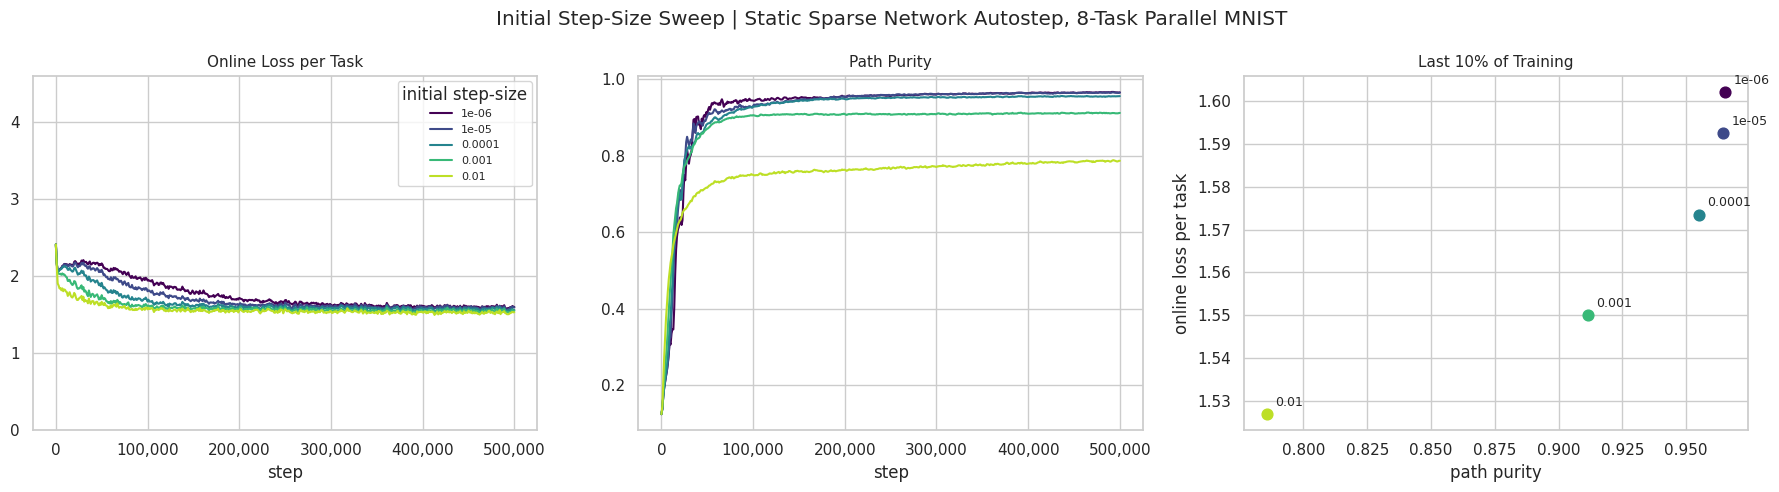

In [11]:
# Initial step-size sweep for static sparse network Autostep: every value trained at once, on the same N_SEEDS seeds. The
# initial step-size alpha_0 also sets the input weights' starting range, U(-alpha_0, alpha_0).
SWEEP_INIT_STEP_SIZES = (1e-6, 1e-5, 1e-4, 1e-3, 1e-2)
SWEEP_STEPS = 500_000
SWEEP_WINDOW = 1000                  # steps per recorded window


def init_step_size_run(init_step_size, key, stream):
    # Static sparse network Autostep (as in autostep_step) with this initial step-size. Returns the online loss per task
    # and the path purity: at step 1, then averaged over every SWEEP_WINDOW steps.
    optimizer = optax_idbd(meta_lr=AUTOSTEP_META_STEP_SIZE, init_lr=init_step_size, autostep=True, tau=AUTOSTEP_TAU,
                           version='squared_inputs')

    def step(carry, _):
        net, stream = carry
        stream, (x, labels) = next_sample(stream)

        def loss_fn(w):
            logits, aux = autostep_forward(w, net, x)
            return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), aux

        w = (net.hidden.w, net.output.w)
        (loss, (sources, state)), grads = jax.value_and_grad(loss_fn, has_aux=True)(w)
        updates, opt = optimizer.update((grads, None, sources), net.opt, w)
        net = net._replace(hidden=net.hidden._replace(w=w[0] + updates[0]),
                           output=net.output._replace(w=w[1] + updates[1]),
                           opt=opt, **state)
        return (net, stream), (loss / N_TASKS, path_purity(*task_weights(net)))

    def window(carry, _):
        carry, values = jax.lax.scan(step, carry, length=SWEEP_WINDOW)
        return carry, jax.tree.map(jnp.mean, values)

    # init_autostep_net's start, with the same input-weight draw rescaled to U(-alpha_0, alpha_0).
    net = init_autostep_net(key)
    hidden = net.hidden._replace(w=net.hidden.w * (init_step_size / AUTOSTEP_INIT_STEP_SIZE))
    net = net._replace(hidden=hidden, opt=optimizer.init((hidden.w, net.output.w)))
    carry, first = step((net, stream), None)
    rest = jax.lax.scan(window, carry, length=SWEEP_STEPS // SWEEP_WINDOW)[1]
    return jax.tree.map(lambda f, r: jnp.concatenate([f[None], r]), first, rest)


over_seeds = jax.vmap(init_step_size_run, in_axes=(None, 0, 0))
sweep_loss, sweep_purity = (np.asarray(v) for v in jax.jit(jax.vmap(over_seeds, in_axes=(0, None, None)))(
    jnp.array(SWEEP_INIT_STEP_SIZES), *seeds()))                  # each (initial step-size, seed, step 1 + window)

sweep_steps = 1 + np.arange(SWEEP_STEPS // SWEEP_WINDOW + 1) * SWEEP_WINDOW
final = slice(-(len(sweep_steps) // 10), None)                   # the last 10% of training
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(SWEEP_INIT_STEP_SIZES)))
for init_step_size, loss, purity, color in zip(SWEEP_INIT_STEP_SIZES, sweep_loss, sweep_purity, colors):
    axes[0].plot(sweep_steps, loss.mean(0), color=color, lw=1.5, label=f'{init_step_size:g}')
    axes[1].plot(sweep_steps, purity.mean(0), color=color, lw=1.5)
    axes[2].scatter(purity[:, final].mean(), loss[:, final].mean(), color=color, s=60)
    axes[2].annotate(f'{init_step_size:g}', (purity[:, final].mean(), loss[:, final].mean()),
                     textcoords='offset points', xytext=(6, 6), fontsize=9)
axes[0].set_ylim(0, 2 * np.log(N_CLASSES))      # up to twice the loss of guessing; anything higher runs off the top
for ax, title in zip(axes[:2], ('Online Loss per Task', 'Path Purity')):
    ax.xaxis.set_major_formatter('{x:,.0f}')
    ax.set_xlabel('step')
    ax.set_title(title, fontsize=11)
axes[2].set_xlabel('path purity')
axes[2].set_ylabel('online loss per task')
axes[2].set_title('Last 10% of Training', fontsize=11)
axes[0].legend(title='initial step-size', fontsize=8)
fig.suptitle(f'Initial Step-Size Sweep | Static Sparse Network Autostep, {N_TASKS}-Task Parallel MNIST')
fig.tight_layout()
plt.show()

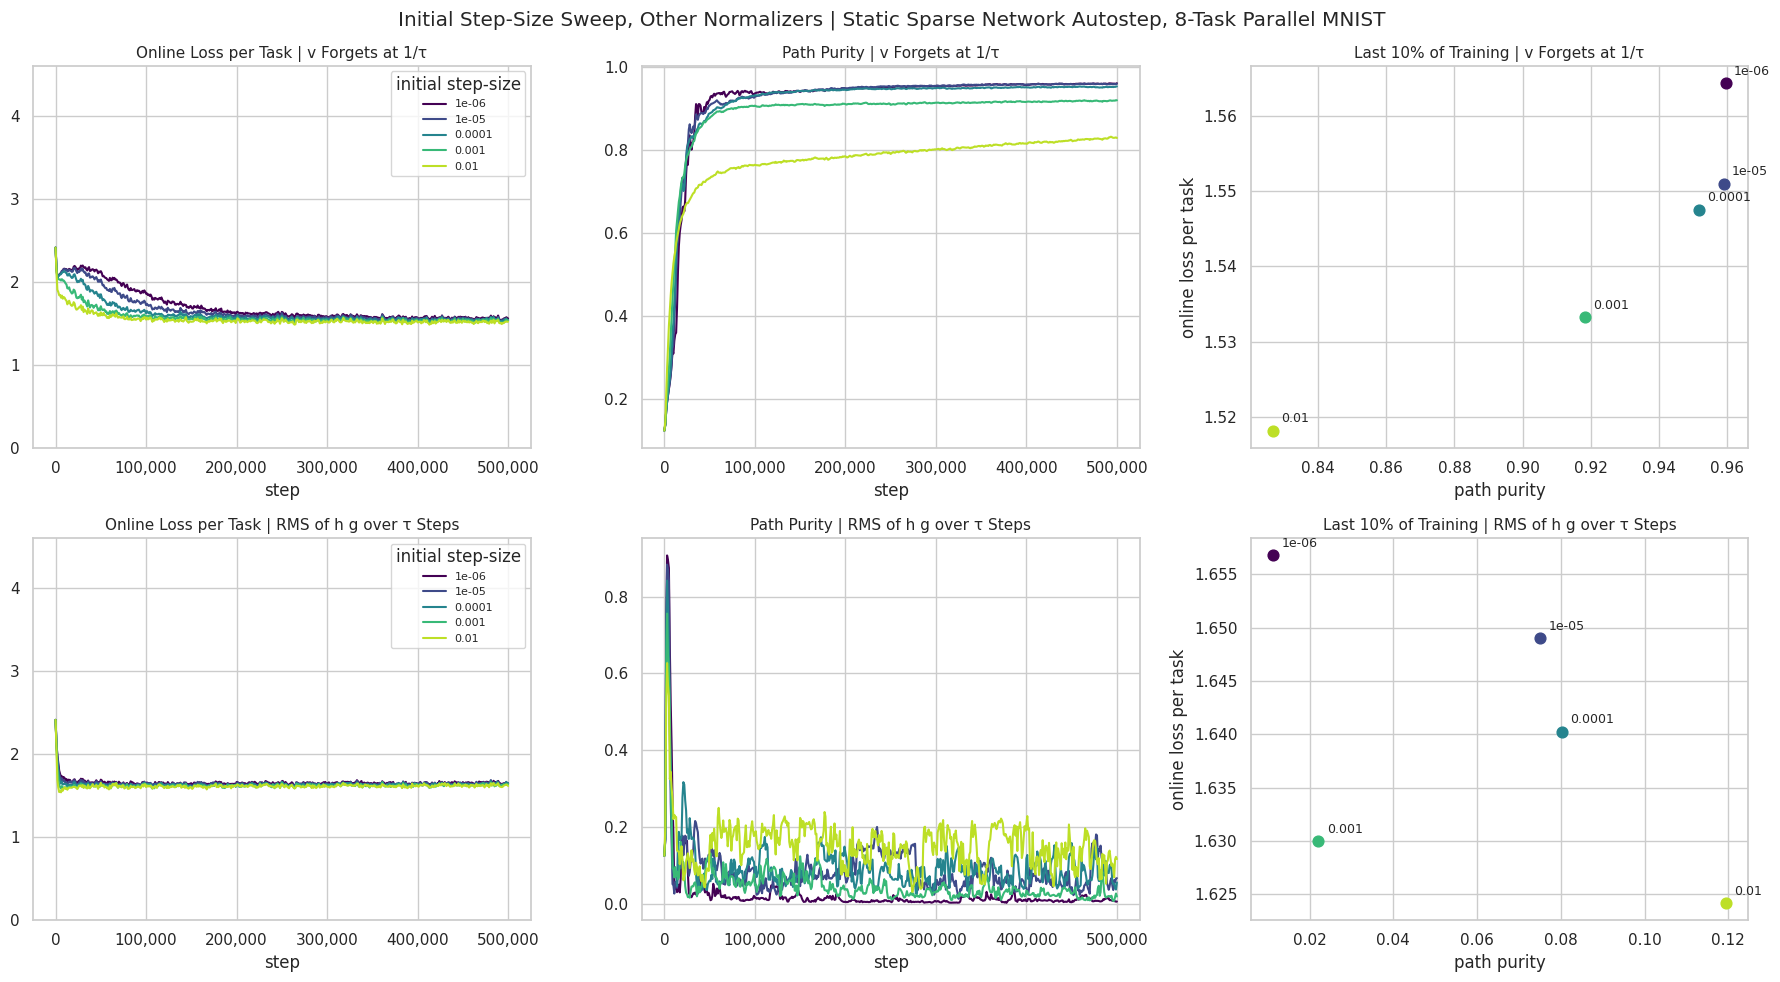

In [12]:
# The initial step-size sweep of the cell above, with two other normalizers for Autostep's meta-gradient h g.
NORMALIZERS = {'decay': 'v Forgets at 1/τ', 'rms': 'RMS of h g over τ Steps'}
VARIANT_INIT_STEP_SIZES = (1e-6, 1e-5, 1e-4, 1e-3, 1e-2)
VARIANT_STEPS = 500_000
VARIANT_WINDOW = 1000                # steps per recorded window


class AutostepState(NamedTuple):
    beta: tuple               # each weight's log step-size, per layer
    h: tuple                  # each weight's trace of recent updates
    v: tuple                  # each weight's normalizer state
    t: jax.Array              # updates so far, for the RMS normalizer's bias correction


def autostep(normalizer, init_step_size, meta_step_size=AUTOSTEP_META_STEP_SIZE):
    # Network Autostep, as optax_idbd(autostep=True, version='squared_inputs'), with a choice of normalizer for the
    # meta-gradient h g: 'max' is Autostep's own (a running max of |h g| that forgets at rate alpha x^2 / tau), 'decay'
    # the same running max forgetting at the fixed rate 1 / tau, and 'rms' the root mean square of h g over about tau
    # steps, bias-corrected like Adam's. Returns (init, update) functions.
    def init(params):
        zeros = jax.tree.map(jnp.zeros_like, params)
        return AutostepState(jax.tree.map(lambda p: jnp.full_like(p, jnp.log(init_step_size)), params), zeros, zeros,
                             jnp.array(0))

    def update(grads, sources, state):
        t = state.t + 1

        def layer(beta, h, v, g, x):
            alpha, x2, hg = jnp.exp(beta), x ** 2, h * g
            if normalizer == 'max':
                v = jnp.maximum(jnp.abs(hg), v + alpha * x2 / AUTOSTEP_TAU * (jnp.abs(hg) - v))
                scale = v
            elif normalizer == 'decay':
                v = jnp.maximum(jnp.abs(hg), v + (jnp.abs(hg) - v) / AUTOSTEP_TAU)
                scale = v
            else:
                v = v + (hg ** 2 - v) / AUTOSTEP_TAU
                scale = jnp.sqrt(v / (1 - (1 - 1 / AUTOSTEP_TAU) ** t))
            meta = meta_step_size * hg / jnp.where(scale > 0, scale, 1.0)
            alpha = jnp.where(scale > 0, alpha * jnp.exp(meta), alpha)
            alpha = alpha / jnp.maximum(jnp.sum(alpha * x2, axis=-1, keepdims=True), 1.0)    # Autostep's per-unit cap
            h = h * jnp.maximum(1 - alpha * x2, 0) + alpha * g
            return jnp.log(alpha), h, v, -alpha * g

        beta, h, v, updates = zip(*map(layer, state.beta, state.h, state.v, grads, sources))
        return updates, AutostepState(beta, h, v, t)

    return init, update


def variant_run(normalizer, init_step_size, key, stream, meta_step_size=AUTOSTEP_META_STEP_SIZE):
    # The cell above's init_step_size_run, with Autostep's normalizer set by `normalizer`.
    init, update = autostep(normalizer, init_step_size, meta_step_size)

    def step(carry, _):
        net, stream = carry
        stream, (x, labels) = next_sample(stream)

        def loss_fn(w):
            logits, aux = autostep_forward(w, net, x)
            return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), aux

        w = (net.hidden.w, net.output.w)
        (loss, (sources, state)), grads = jax.value_and_grad(loss_fn, has_aux=True)(w)
        updates, opt = update(grads, sources, net.opt)
        net = net._replace(hidden=net.hidden._replace(w=w[0] + updates[0]),
                           output=net.output._replace(w=w[1] + updates[1]),
                           opt=opt, **state)
        return (net, stream), (loss / N_TASKS, path_purity(*task_weights(net)))

    def window(carry, _):
        carry, values = jax.lax.scan(step, carry, length=VARIANT_WINDOW)
        return carry, jax.tree.map(jnp.mean, values)

    net = init_autostep_net(key)
    hidden = net.hidden._replace(w=net.hidden.w * (init_step_size / AUTOSTEP_INIT_STEP_SIZE))
    net = net._replace(hidden=hidden, opt=init((hidden.w, net.output.w)))
    carry, first = step((net, stream), None)
    rest = jax.lax.scan(window, carry, length=VARIANT_STEPS // VARIANT_WINDOW)[1]
    return jax.tree.map(lambda f, r: jnp.concatenate([f[None], r]), first, rest)


variant_results = {}                 # normalizer -> (loss, purity), each (initial step-size, seed, step 1 + window)
for normalizer in NORMALIZERS:
    over_seeds = jax.vmap(lambda a, key, stream: variant_run(normalizer, a, key, stream), in_axes=(None, 0, 0))
    variant_results[normalizer] = [np.asarray(v) for v in jax.jit(jax.vmap(over_seeds, in_axes=(0, None, None)))(
        jnp.array(VARIANT_INIT_STEP_SIZES), *seeds())]

variant_steps = 1 + np.arange(VARIANT_STEPS // VARIANT_WINDOW + 1) * VARIANT_WINDOW
final = slice(-(len(variant_steps) // 10), None)                 # the last 10% of training
colors = plt.cm.viridis(np.linspace(0, 0.9, len(VARIANT_INIT_STEP_SIZES)))
fig, axes = plt.subplots(len(NORMALIZERS), 3, figsize=(18, 5 * len(NORMALIZERS)))
for row, (normalizer, name) in zip(axes, NORMALIZERS.items()):
    for init_step_size, loss, purity, color in zip(VARIANT_INIT_STEP_SIZES, *variant_results[normalizer], colors):
        row[0].plot(variant_steps, loss.mean(0), color=color, lw=1.5, label=f'{init_step_size:g}')
        row[1].plot(variant_steps, purity.mean(0), color=color, lw=1.5)
        row[2].scatter(purity[:, final].mean(), loss[:, final].mean(), color=color, s=60)
        row[2].annotate(f'{init_step_size:g}', (purity[:, final].mean(), loss[:, final].mean()),
                        textcoords='offset points', xytext=(6, 6), fontsize=9)
    row[0].set_ylim(0, 2 * np.log(N_CLASSES))  # up to twice the loss of guessing; anything higher runs off the top
    for ax, title in zip(row[:2], ('Online Loss per Task', 'Path Purity')):
        ax.xaxis.set_major_formatter('{x:,.0f}')
        ax.set_xlabel('step')
        ax.set_title(f'{title} | {name}', fontsize=11)
    row[2].set_xlabel('path purity')
    row[2].set_ylabel('online loss per task')
    row[2].set_title(f'Last 10% of Training | {name}', fontsize=11)
    row[0].legend(title='initial step-size', fontsize=8)
fig.suptitle(f'Initial Step-Size Sweep, Other Normalizers | Static Sparse Network Autostep, {N_TASKS}-Task Parallel MNIST')
fig.tight_layout()
plt.show()

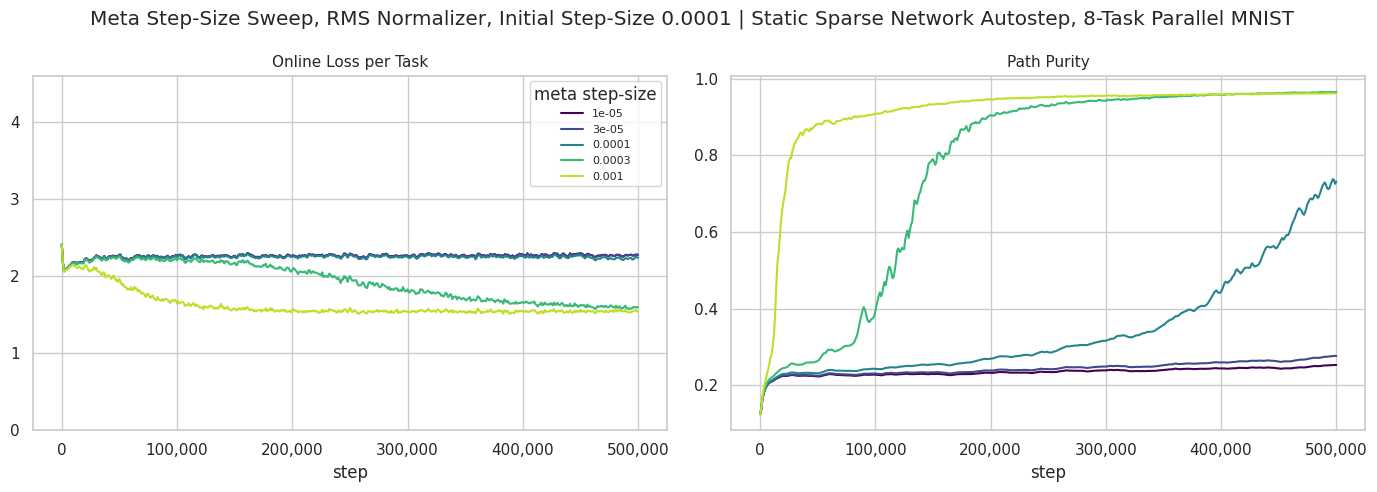

In [13]:
# The RMS normalizer's meta-steps are about +-1 times the meta step-size, far larger than the max normalizer's |h g| / v,
# so it needs a smaller meta step-size. A sweep at the notebook's initial step-size, over the cell above's VARIANT_STEPS.
RMS_META_STEP_SIZES = (1e-5, 3e-5, 1e-4, 3e-4, 1e-3)

over_seeds = jax.vmap(lambda meta, key, stream: variant_run('rms', AUTOSTEP_INIT_STEP_SIZE, key, stream, meta),
                      in_axes=(None, 0, 0))
rms_loss, rms_purity = (np.asarray(v) for v in jax.jit(jax.vmap(over_seeds, in_axes=(0, None, None)))(
    jnp.array(RMS_META_STEP_SIZES), *seeds()))                    # each (meta step-size, seed, step 1 + window)

steps = 1 + np.arange(VARIANT_STEPS // VARIANT_WINDOW + 1) * VARIANT_WINDOW
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(RMS_META_STEP_SIZES)))
for meta_step_size, loss, purity, color in zip(RMS_META_STEP_SIZES, rms_loss, rms_purity, colors):
    axes[0].plot(steps, loss.mean(0), color=color, lw=1.5, label=f'{meta_step_size:g}')
    axes[1].plot(steps, purity.mean(0), color=color, lw=1.5)
axes[0].set_ylim(0, 2 * np.log(N_CLASSES))      # up to twice the loss of guessing; anything higher runs off the top
for ax, title in zip(axes, ('Online Loss per Task', 'Path Purity')):
    ax.xaxis.set_major_formatter('{x:,.0f}')
    ax.set_xlabel('step')
    ax.set_title(title, fontsize=11)
axes[0].legend(title='meta step-size', fontsize=8)
fig.suptitle(f'Meta Step-Size Sweep, RMS Normalizer, Initial Step-Size {AUTOSTEP_INIT_STEP_SIZE:g} | '
             f'Static Sparse Network Autostep, {N_TASKS}-Task Parallel MNIST')
fig.tight_layout()
plt.show()